In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch
import xarray as xa
import cartopy.crs as ccrs

import sys,os
testdir = os.path.dirname(os.getcwd() + '/')
srcdir = '..'
sys.path.insert(0, os.path.abspath(os.path.join(testdir, srcdir)))
from ocean_wave_tracing import Wave_tracing

from ocean_wave_tracing.util_metric import *

plt.rcParams.update({
    'font.size': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 20,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'mathtext.fontset': 'cm',
    'font.family': 'serif',
    'text.usetex': True
})


import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:

import torch as t
import numpy as np
import matplotlib.pyplot as plt


def plot_stereographic_grid(projection, title, lat_range=(50, 90),
                            lon_range=(-180, 180),
                            n_lat=19, n_lon=37):
    """
    Create a regular latitude-longitude grid, transform it,
    and plot the projected grid lines and intersection points.

    Angles are specified in degrees here and converted to radians.
    """
    # Create regular latitude-longitude coordinates
    lats = np.linspace(*lat_range, n_lat)
    lons = np.linspace(*lon_range, n_lon)
    lon_grid, lat_grid = np.meshgrid(lons, lats)

    # Convert to radians and then to PyTorch tensors
    lat = t.tensor(np.deg2rad(lat_grid), dtype=t.float64)
    lon = t.tensor(np.deg2rad(lon_grid), dtype=t.float64)

    # Transform every grid point
    with t.no_grad():
        x = projection.x(lon, lat)
        y = projection.y(lon, lat)

    # Convert projected coordinates to NumPy for plotting
    x = x.detach().cpu().numpy()
    y = y.detach().cpu().numpy()

    # Plot transformed grid
    fig, ax = plt.subplots(figsize=(10, 8))

    # Lines of constant latitude
    for i in range(n_lat):
        if i==int(n_lat*2/3):
            ax.plot(x[i, :], y[i, :], color="teal", 
                    linewidth=3, alpha=0.7, label=f"{lats[i]:.2f}$^\circ$")
        elif i==int(n_lat*2.2/3):
                    ax.plot(x[i, :], y[i, :], color="goldenrod", 
                            linewidth=3, alpha=0.7, label=f"{lats[i]:.2f}$^\circ$")
        else:
            ax.plot(x[i, :], y[i, :], color="black",
                     linewidth=0.8, alpha=0.7)

    # Lines of constant longitude
    for j in range(n_lon):
        if j==int(n_lon*4/5):
            ax.plot(x[:, j], y[:, j], color="firebrick",
                            linewidth=3, alpha=0.7, label=f"{lons[j]:.2f}$^\circ$")
        elif j==int(n_lon*2.75/5):
                    ax.plot(x[:, j], y[:, j], color="limegreen",
                                    linewidth=3, alpha=0.7, label=f"{lons[j]:.2f}$^\circ$")
        else:
            ax.plot(x[:, j], y[:, j], color="black",
                    linewidth=0.8, alpha=0.7)

    # Plot all transformed grid points
    #ax.scatter(x, y, s=8, color="black", zorder=3)

    ax.set_title(title)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.2)
    ax.legend()
    return fig, ax




<>:40: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:43: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:52: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:55: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:40: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:43: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:52: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences wil

[  10.           10.           10.         ... 2805.37999178 2804.3010555
 2803.20168161]


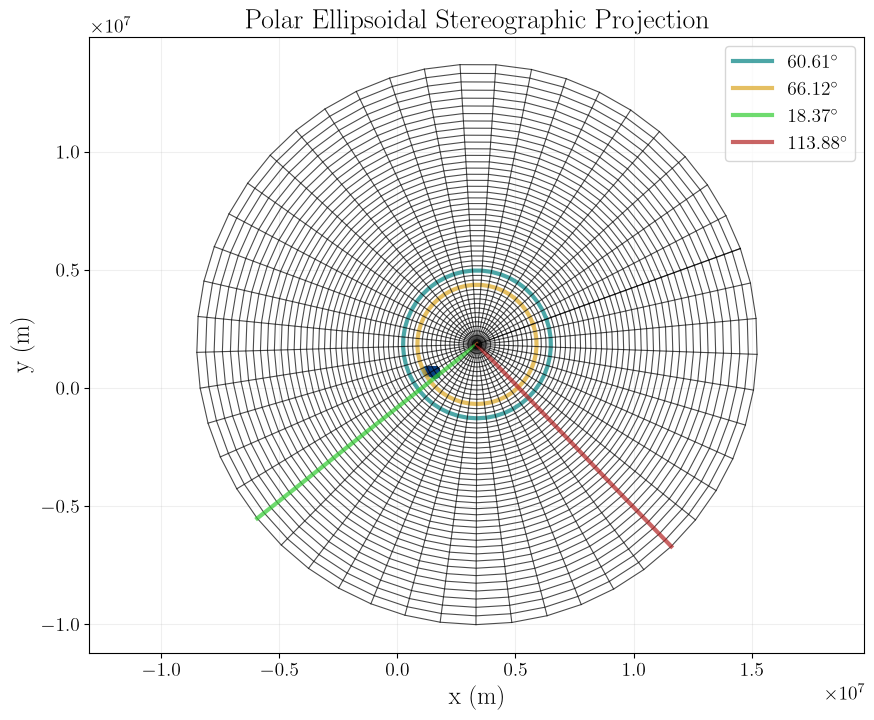

In [3]:
#%matplotlib widget

dataset = xa.open_dataset("example_ambient_conditions/nk_subset_NK_new.nc")
lofoten_h = dataset.h.values
analysis_date = '2026-04-02T01'
lofoten_x, lofoten_y = np.meshgrid(dataset.X.data, dataset.Y.data)
lofoten_x = lofoten_x.flatten()
lofoten_y = lofoten_y.flatten()
lofoten_h = lofoten_h.flatten()

polar_proj2 = PolarEllipsoidStereographicProjection(lat_0=np.deg2rad(90), lon_0=np.deg2rad(70), lat_t=np.deg2rad(60), x_0=3369600, y_0=1844800, a=6378137, b=6356752.3142)

fig, ax = plot_stereographic_grid(polar_proj2, "Polar Ellipsoidal Stereographic Projection", lat_range=(0, 90), n_lat=50, n_lon=50)
#ax.set_xlim([0, 2e6])
#ax.set_ylim([0, 2e6])
ax.scatter(lofoten_x, lofoten_y, c=lofoten_h, cmap="Blues")#, levels=np.arange(20,400,20), extend="max")
print(lofoten_h)
plt.show()

In [4]:
dataset

<xarray.Dataset> Size: 43MB
Dimensions:           (time: 12, Y: 400, X: 500)
Coordinates:
  * time              (time) datetime64[ns] 96B 2026-04-02T12:00:00 ... 2026-...
  * Y                 (Y) int32 2kB 400000 400800 401600 ... 718400 719200
  * X                 (X) int32 2kB 1200000 1200800 1201600 ... 1598400 1599200
    lon               (Y, X) float64 2MB ...
    lat               (Y, X) float64 2MB ...
    depth             float64 8B ...
Data variables:
    u_eastward        (time, Y, X) float32 10MB ...
    v_northward       (time, Y, X) float32 10MB ...
    h                 (Y, X) float64 2MB 10.0 10.0 10.0 ... 2.804e+03 2.803e+03
    projection_stere  int32 4B ...
    Uwind_eastward    (time, Y, X) float32 10MB ...
    Vwind_northward   (time, Y, X) float32 10MB ...
Attributes: (12/40)
    id:                         a29afe2d-e028-451b-bf83-546456a7be94
    naming_authority:           no.met
    operational_status:         Operational
    iso_topic_category:         oceans
    activity_type:              Numerical Simulation
    keywords_vocabulary:        GCMDSK:GCMD Science Keywords:https://gcmd.ear...
    ...                         ...
    summary:                    Norkyst_v3-800m (Norwegian Coast 800m horizon...
    title_no:                   120 timers prognoser fra havmodellen Norkyst_...
    summary_no:                 NorKyst_v3-800m (Norske kystområder med 800m ...
    contributor_name:           Magne Simonsen, Mateusz Matuszak
    contributor_role:           Technical contact, Metadata author
    contributor_email:          magnes@met.no, mateuszm@met.no

In [5]:
from pyproj import CRS, Transformer
import numpy as np

crs = CRS.from_proj4(
    "+proj=stere +lat_0=90 +lat_ts=60 +lon_0=70 "
    "+x_0=3369600 +y_0=1844800 "
    "+a=6378137 +b=6356752.3142 +units=m +type=crs"
)

transformer = Transformer.from_crs(
    crs, "EPSG:4326", always_xy=True
)

lon, lat = transformer.transform(
    dataset.X.values, 
    np.full(dataset.X.shape, dataset.Y.values[0])
)